# Домашнее задание 2. Вариант NLP: NER - детекция в тексте

**Дедлайн:** вс 22.11.2026, 23:59

В ДЗ2 вы выбираете **один** вариант: CV (детекция объектов на YOLO) или NLP (этот ноутбук). Номера задач и баллы в вариантах совпадают. NER (named entity recognition) - это детекция в тексте: найти спаны, т.е. непрерывные куски из слов, и для каждого предсказать тип сущности. Вы берете предобученный энкодер с Hugging Face Hub, находите свой датасет, приводите разметку к формату модели, дообучаете, считаете метрики и разбираете ошибки.

- Заполняйте места с `# ваш код` и ячейки «**Ответ:**». Сигнатуры функций и открытые тесты не меняйте, свои ячейки добавлять можно. Открытые тесты проверяют часть контракта, при проверке будут и другие входы
- В ответах опирайтесь на свои числа: наблюдение, объяснение, ограничение вывода. Обычно хватает 2-4 предложений. Отсутствие ожидаемого эффекта - нормальный результат, если эксперимент корректный и вы это обсудили
- Свой код обязателен в 1.2 (параметры по блокам), 2.2 (конвертация разметки + тесты), 3.1 (словарный бейзлайн), 5.1 (категоризация ошибок). Для обучения и стандартных метрик можно `transformers` (`Trainer` или свой цикл) и `seqeval`
- `FAST_MODE = True` - отладка на маленьком подмножестве, весь ноутбук не дольше 5 минут на T4. Финальный прогон - с `FAST_MODE = False`, ориентир до ~1 часа на T4. Бонусы включаются через `BONUS_TASKS`, выключенные бонусы пропускаются, даже если их ячейки пустые
- Запуск: Colab (T4) или Kaggle (GPU T4, ноутбук сам берет одну карту). Зависимости ставит первая ячейка, пины те же, что в `requirements_nlp.txt`. Укажите устройство в ячейке ниже, время обучения возвращает ваш `train_ner` (4.1)
- Только открытые модели и данные. Лицензию модели и датасета укажите в 1.1 и 2.1
- Можно документацию, материалы курса и код семинаров - укажите источник
- Сдача как в ДЗ1: PR в свой публичный GitHub-репозиторий, ссылка на него - в Google-форму (ссылку на форму дадим отдельно). В PR - ноутбук с outputs и `artifacts/metrics.json` (пишется в 5.3, перед бонусами). Датасет (`data/`), `runs/` и веса моделей не кладите, достаточно кода скачивания; файл доразметки из 6.1 - кладите
- Для полной сдачи: Restart & Run All с `FAST_MODE = False`, сохранить outputs. Если сдаете частичное решение, перечислите нерешенные задачи в ячейке ниже и приложите то, что получилось. Ошибки не скрывайте: баллы ставятся по задачам, одна ошибка не обнуляет остальные
- ДЗ индивидуальное

| раздел | задачи | баллы |
|---|---|---|
| 1. Модель | 1.1 модель и ревизия · 1.2 архитектура | 4 |
| 2. Данные | 2.1 датасет · 2.2 формат разметки | 4 |
| 3. Бейзлайн | 3.1 бейзлайн до дообучения | 2 |
| 4. Дообучение | 4.1 обучение · 4.2 метрики | 6 |
| 5. Анализ | 5.1 разбор ошибок · 5.2 абляция · 5.3 выводы | 4 |
| 6*. Бонусы | 6.1 доразметка · 6.2 другая модель · 6.3 сдвиг · 6.4 экспорт и скорость · 6.5 пороги | до +4 из 5.5 |
| итого | | 20 + 4 |

Соответствие с CV-вариантом - задачи те же, меняется «геометрия»: вместо прямоугольника на картинке - отрезок из слов в предложении.

| CV (детекция на картинке) | NLP (NER в тексте) |
|---|---|
| бокс | спан: (начало, конец, тип) в индексах слов |
| класс объекта | тип сущности (PER, ORG, LOC, ...) |
| фон | тег `O` |
| VOC / COCO -> YOLO-формат | слова и спаны -> BIO-теги под сабворды токенизатора |
| backbone -> neck -> head | эмбеддинги -> слои энкодера -> голова token classification |
| mAP по IoU | F1 по сущностям (`seqeval`, спан засчитывается при точном совпадении границ и типа) |
| ошибка локализации (IoU 0.1-0.5) | ошибка границы спана (тип верный, спаны пересекаются) |
| ошибка класса | ошибка типа |
| пропуск / лишний бокс | пропуск / лишний спан |
| порог conf | порог уверенности спана |

Внутренности трансформера (attention, устройство слоя энкодера) - тема ДЗ3. Здесь энкодер рассматривается на уровне блоков.

Примерный план: первая неделя - разделы 1-3 (модель, датасет, разметка, бейзлайн), вторая - обучение, метрики, разбор ошибок, абляция и финальный прогон.

**Сведения о сдаче.** Укажите устройство (Colab T4 / Kaggle / свое), выбранные модель и датасет (ссылка и лицензия), бонусы, внешние источники и нерешенные задачи (если есть).

**Ответ:** Локальный CPU Intel Core Ultra 5 125H (4 потока). Модель [BERT 2/128](https://huggingface.co/google/bert_uncased_L-2_H-128_A-2/tree/30b0a37ccaaa32f332884b96992754e246e48c5f), Apache 2.0. Датасет [WNUT‑17](https://huggingface.co/datasets/leondz/wnut_17), CC BY 4.0. Выполняются бонусы 6.2–6.5. Бонус 6.1 не выбран.

Источники — [статья WNUT‑17](https://aclanthology.org/W17-4418/), [статья о компактных BERT](https://arxiv.org/abs/1908.08962), документация [Transformers Trainer](https://huggingface.co/docs/transformers/main_classes/trainer) и [seqeval](https://github.com/chakki-works/seqeval).

In [1]:
# Зависимости (пины те же, что в requirements_nlp.txt). Запускайте эту ячейку первой, тогда перезапуск сессии не нужен
# Безвредный шум: строки ERROR от pip про bigframes / cudf / pyarrow на Kaggle и предупреждение про HF_TOKEN ниже (токен не нужен)
# Локально: сначала torch под свою платформу (https://pytorch.org/get-started/locally/)
%pip install -q "torch>=2.4" "transformers==5.22.1" "datasets==5.1.0" "accelerate==1.15.0" "seqeval==1.2.2" numpy matplotlib

Note: you may need to restart the kernel to use updated packages.


  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.

[notice] A new release of pip is available: 26.1.2 -> 26.3
[notice] To update, run: C:\Users\Mi\AppData\Local\Python\pythoncore-3.14-64\python.exe -m pip install --upgrade pip


In [2]:
import os
os.environ.setdefault('CUDA_VISIBLE_DEVICES', '0')   # одна GPU: на Kaggle T4 x2 иначе Trainer включит DataParallel (медленнее и хуже)
import collections
import copy
import json
import math
import random
import re
import time
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import torch

import datasets
import transformers
from datasets import DatasetDict, load_dataset
from huggingface_hub import HfApi
from seqeval.metrics import classification_report, f1_score, precision_score, recall_score
from transformers import (AutoModelForTokenClassification, AutoTokenizer, DataCollatorForTokenClassification,
                          Trainer, TrainingArguments)

transformers.logging.set_verbosity_error()
plt.rcParams['figure.dpi'] = 100
plt.rcParams['font.size'] = 11

print(f'torch {torch.__version__}, transformers {transformers.__version__}, datasets {datasets.__version__}')
print(f'CUDA available: {torch.cuda.is_available()}')

C:\Users\Mi\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
W1122 16:13:25.434000 38372 site-packages\torch\distributed\elastic\multiprocessing\redirects.py:29] NOTE: Redirects are currently not supported in Windows or MacOs.


torch 2.11.0+cpu, transformers 5.22.1, datasets 5.1.0
CUDA available: False


In [3]:
def get_device():
    if torch.cuda.is_available():
        return torch.device('cuda')
    if torch.backends.mps.is_available():
        return torch.device('mps')
    return torch.device('cpu')


def set_seed(seed=0):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    transformers.set_seed(seed)


device = get_device()
DEVICE_NAME = torch.cuda.get_device_name(0) if device.type == 'cuda' else device.type
if device.type == 'cpu':
    torch.set_num_threads(min(4, os.cpu_count() or 1))
set_seed(0)
print(device, DEVICE_NAME)

cpu cpu


In [4]:
FAST_MODE = False   # True - отладка, False - финальный прогон
BONUS_TASKS = {'6.2', '6.3', '6.4', '6.5'}
assert BONUS_TASKS <= {'6.1', '6.2', '6.3', '6.4', '6.5'}

SEED = 0
N_TRAIN = 2000 if FAST_MODE else None   # None - весь train
N_EVAL = 500 if FAST_MODE else None     # подмножество validation и test в FAST_MODE
EPOCHS = 1 if FAST_MODE else 3
MAX_LENGTH = 128                        # длина в сабвордах, длиннее - обрезается
ARTIFACTS = Path('artifacts')
ARTIFACTS.mkdir(exist_ok=True)
RUN_TIMES = {}

---
# 1. Модель

## 1.1 Модель и ревизия (1.5 балла)

Выберите предобученный энкодер на Hugging Face Hub, подходящий под язык и домен вашего датасета. Модель на Hub - это git-репозиторий: владелец может перезалить веса, токенизатор или конфиг, и `main` начнет указывать на другую версию. Поэтому зафиксируйте `revision` - полный commit hash (40 символов). Его видно во вкладке «Files and versions» -> «History» или через `HfApi().model_info(MODEL_ID).sha`.

Ориентиры для выбора (не исчерпывающий список):
- русский: `cointegrated/rubert-tiny2` (29M параметров, быстрый), `DeepPavlov/rubert-base-cased` (~180M)
- многоязычные: `FacebookAI/xlm-roberta-base` (~280M), `google-bert/bert-base-multilingual-cased` (~180M), `distilbert/distilbert-base-multilingual-cased`
- английский: `google-bert/bert-base-cased`, `FacebookAI/roberta-base` (в 1.1 задайте `TOKENIZER_KWARGS = {'add_prefix_space': True}`), `microsoft/deberta-v3-small`
- биомедицина: `dmis-lab/biobert-base-cased-v1.2`

Нужен fast-токенизатор: `word_ids()`, без которого не выровнять метки по сабвордам, есть только у него. На T4 модель до ~300M параметров дообучается на датасете в десятки тысяч предложений за минуты - десятки минут.

Нужен базовый энкодер, а не модель, уже дообученная на NER: с ней 3.1 и 4.1 теряют смысл.

In [5]:
MODEL_ID = 'google/bert_uncased_L-2_H-128_A-2'
REVISION = '30b0a37ccaaa32f332884b96992754e246e48c5f'
TOKENIZER_KWARGS = {}

In [6]:
assert MODEL_ID, 'укажите MODEL_ID'
assert re.fullmatch(r'[0-9a-f]{40}', REVISION or ''), 'REVISION - полный commit hash из 40 символов, а не main и не тег'
info = HfApi().model_info(MODEL_ID, revision=REVISION, files_metadata=True)
card = info.card_data.to_dict() if info.card_data else {}
weights = {s.rfilename: f'{s.size / 2**20:.0f} MB' for s in info.siblings if s.rfilename.endswith(('.safetensors', '.bin'))}
print(f'model:    {MODEL_ID}\nrevision: {info.sha}\nlicense:  {card.get("license")}\nlanguage: {card.get("language")}')
print(f'updated:  {info.last_modified}\nweights:  {weights}')

tokenizer = AutoTokenizer.from_pretrained(MODEL_ID, revision=REVISION, **TOKENIZER_KWARGS)
assert tokenizer.is_fast, 'нужен fast-токенизатор: word_ids() есть только у него'
print(type(tokenizer).__name__, 'vocab size', tokenizer.vocab_size)
print(tokenizer.tokenize('Петр Ильич Чайковский родился в Воткинске'))

model:    google/bert_uncased_L-2_H-128_A-2
revision: 30b0a37ccaaa32f332884b96992754e246e48c5f
license:  apache-2.0
language: None
updated:  2023-09-05 15:25:24+00:00
weights:  {'model.safetensors': '17 MB', 'pytorch_model.bin': '17 MB'}


C:\Users\Mi\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\Mi\.cache\huggingface\hub\models--google--bert_uncased_L-2_H-128_A-2. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


BertTokenizer vocab size 30522
['п', '##е', '##т', '##р', 'и', '##л', '##ь', '##и', '##ч', 'ч', '##а', '##и', '##к', '##ов', '##с', '##к', '##ии', 'р', '##о', '##д', '##и', '##л', '##с', '##я', 'в', 'в', '##о', '##т', '##к', '##и', '##н', '##с', '##к', '##е']


**Вопрос.** Почему вы выбрали эту модель: язык и данные предобучения, размер и скорость, ожидаемое качество на NER, лицензия? Сравните с 1-2 альтернативами из списка выше: размер, язык, скорость, качество по карточке. Что может сломаться в вашем ноутбуке через полгода, если не фиксировать `revision`?

**Ответ:** BERT 2/128 предобучен на английских BooksCorpus и Википедии с маскированием WordPiece. Он подходит по языку и быстро обучается на CPU, хотя домен соцсетей отличается, а uncased-токенизатор теряет подсказку в виде регистра. [BERT base cased](https://huggingface.co/google-bert/bert-base-cased) крупнее (около 108 млн параметров против 4,4 млн) и потенциально точнее за счёт ёмкости и регистра, но потребует больше вычислений. Карточки не дают сопоставимых оценок на WNUT‑17. Модель распространяется под Apache 2.0. Фиксация ревизии защищает результаты от будущих изменений весов, конфига и токенизатора.

## 1.2 Архитектура (2.5 балла)

Энкодер для token classification на уровне блоков:

1. **эмбеддинги** - сабворд -> вектор размера hidden (таблица `vocab_size x hidden`) + позиционные эмбеддинги (у DeBERTa их нет, позиции учитываются в attention) и type-эмбеддинги (у BERT-подобных), LayerNorm, dropout. Выход `(B, T, H)`
2. **N слоев энкодера** - одинаковые по форме блоки `(B, T, H) -> (B, T, H)`, в которых токены обмениваются информацией друг с другом. Устройство слоя (attention, FFN) - ДЗ3
3. **голова token classification** - dropout + `Linear(H, K)` к каждому токену независимо, K - число BIO-тегов. Выход - logits `(B, T, K)`
4. **сборка спанов** - argmax по тегам на первом сабворде каждого слова, затем BIO -> спаны (это уже не нейросеть, а ваш код из 2.2)

Ниже модель создается с головой на `N_DEMO_LABELS = 7` тегов (O + B/I для трех типов), под ваш датасет голову пересоздает `make_model` (3.1, 4.1).

1. Реализуйте `params_by_block(model)` - число параметров по блокам: `embeddings`, `encoder` (все слои), `head` (классификатор), `other` (все остальное: у BERT и RoBERTa для token classification здесь 0, у DeBERTa - `encoder.rel_embeddings` и общий `encoder.LayerNorm`) и `layers` - список по слоям энкодера. Сумма блоков должна совпасть с общим числом параметров
2. Прогоните dummy-вход `demo_texts` (батч из двух предложений, уже разбитых на слова) через токенизатор и модель с `output_hidden_states=True`, сохраните результат токенизатора в `enc`, выход модели в `out` и выведите формы: `input_ids`, `attention_mask`, все `hidden_states`, `logits`

In [7]:
N_DEMO_LABELS = 7
demo_model = AutoModelForTokenClassification.from_pretrained(MODEL_ID, revision=REVISION, num_labels=N_DEMO_LABELS)
cfg = demo_model.config
print({k: getattr(cfg, k, None) for k in ['model_type', 'vocab_size', 'hidden_size', 'num_hidden_layers',
                                          'num_attention_heads', 'intermediate_size', 'max_position_embeddings']})
for name, module in demo_model.named_children():
    print(f'{name:<12} {type(module).__name__}')

C:\Users\Mi\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\Mi\.cache\huggingface\hub. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)
Loading weights: 100%|██████████| 37/37 [00:00<00:00, 4996.43it/s]

{'model_type': 'bert', 'vocab_size': 30522, 'hidden_size': 128, 'num_hidden_layers': 2, 'num_attention_heads': 2, 'intermediate_size': 512, 'max_position_embeddings': 512}
bert         BertModel
dropout      Dropout
classifier   Linear


In [8]:
def params_by_block(model):
    base = model.base_model
    encoder = getattr(base, 'encoder', None)
    if encoder is None:
        encoder = base.transformer

    def count(module):
        return sum(p.numel() for p in module.parameters())

    layers = [count(layer) for layer in encoder.layer]
    embeddings = count(base.embeddings)
    head = count(model.classifier)
    encoder_count = sum(layers)
    return dict(embeddings=embeddings, encoder=encoder_count, head=head, layers=layers,
                other=count(model) - embeddings - encoder_count - head)

In [9]:
blocks = params_by_block(demo_model)
total = sum(p.numel() for p in demo_model.parameters())
assert sum(blocks[k] for k in ['embeddings', 'encoder', 'head', 'other']) == total
assert blocks['head'] == cfg.hidden_size * N_DEMO_LABELS + N_DEMO_LABELS
assert len(blocks['layers']) == cfg.num_hidden_layers and sum(blocks['layers']) == blocks['encoder'], \
    'encoder - сумма слоев, все вне слоев (например, rel_embeddings у DeBERTa) - в other'
assert blocks['embeddings'] >= cfg.vocab_size * cfg.hidden_size
for k in ['embeddings', 'encoder', 'head', 'other']:
    print(f'{k:<11}{blocks[k]:>13,}  {blocks[k] / total:6.1%}')
print(f'{"total":<11}{total:>13,}\nper layer: {blocks["layers"]}')

embeddings     3,972,864   90.9%
encoder          396,544    9.1%
head                 903    0.0%
other                  0    0.0%
total          4,370,311
per layer: [198272, 198272]


In [10]:
demo_texts = [['Петр', 'Чайковский', 'родился', 'в', 'Воткинске', '.'],
              ['ITMO', 'University', 'is', 'in', 'Saint', 'Petersburg']]
enc = tokenizer(demo_texts, is_split_into_words=True, padding=True, return_tensors='pt')
demo_model.eval()
with torch.inference_mode():
    out = demo_model(**enc, output_hidden_states=True)

print('input_ids:', tuple(enc['input_ids'].shape))
print('attention_mask:', tuple(enc['attention_mask'].shape))
print('hidden_states:', [tuple(h.shape) for h in out.hidden_states])
print('logits:', tuple(out.logits.shape))

input_ids: (2, 32)
attention_mask: (2, 32)
hidden_states: [(2, 32, 128), (2, 32, 128), (2, 32, 128)]
logits: (2, 32, 7)


In [11]:
B, T = enc['input_ids'].shape
assert B == 2 and out.logits.shape == (B, T, N_DEMO_LABELS)
assert len(out.hidden_states) == cfg.num_hidden_layers + 1
assert all(h.shape == (B, T, cfg.hidden_size) for h in out.hidden_states)

# скорость прямого прохода: батч 32 предложения x 62 слова (сколько это сабвордов - см. вывод)
x = {k: v.to(device) for k, v in tokenizer([['слово'] * 62] * 32, is_split_into_words=True, return_tensors='pt').items()}
demo_model.to(device).eval()
with torch.inference_mode():
    demo_model(**x)
    if device.type == 'cuda':
        torch.cuda.synchronize()
    start = time.perf_counter()
    for _ in range(5):
        demo_model(**x)
    if device.type == 'cuda':
        torch.cuda.synchronize()
print(f'forward 32 x {x["input_ids"].shape[1]}: {(time.perf_counter() - start) / 5 * 1000:.1f} ms на {DEVICE_NAME}')
demo_model = demo_model.cpu()

forward 32 x 250: 257.8 ms на cpu


**Вопрос.** Опишите путь входа по блокам с формами тензоров из вашего вывода. Какой блок содержит больше всего параметров и почему? В каком блоке токены обмениваются информацией, а где каждый токен обрабатывается независимо? Почему `T` в logits больше числа слов?

**Ответ:** Вход и маска имеют форму (2, 32). Эмбеддинги и выходы двух слоёв энкодера имеют форму (2, 32, 128), голова выдаёт (2, 32, 7). Эмбеддинги занимают 3 972 864 параметра (90,9%) из-за таблицы словаря на 30 522 сабворда. Токены обмениваются информацией в энкодере, а голова применяет одну линейную проекцию к каждой позиции. Длина 32 включает сабворды, спецтокены и дополнение до общей длины батча.

---
# 2. Данные

## 2.1 Датасет (1.5 балла)

Найдите датасет для NER на Hugging Face Hub или в другом открытом источнике, подходящий под вашу модель по языку. Опишите источник, лицензию, как размечали, типы сущностей, размер и сплиты; посчитайте статистику: число сущностей каждого типа по сплитам, распределение длин спанов (в словах), длины предложений.

**Нельзя брать WikiANN ru** (`unimelb-nlp/wikiann`, конфиг `ru`) - на нем ниже показан пример формата. Другие языки WikiANN брать можно.

Подсказки - датасеты, которые на момент выдачи загружаются текущей библиотекой `datasets` (проверено 31.10.2026, `datasets` 5.1). Библиотека больше не исполняет loading-скрипты, поэтому часть датасетов грузится из служебной ветки с parquet-версией - так, как написано в списке:

Русский:
- `Babelscape/wikineural` - WikiNEuRal, PER / ORG / LOC / MISC, 9 языков; для русского сплиты `train_ru`, `val_ru`, `test_ru`; CC BY-NC-SA 4.0
- `Babelscape/multinerd` - MultiNERD, 15 типов, 10 языков, колонка `lang` - отфильтруйте `ru`; CC BY-NC-SA 4.0
- `load_dataset('RCC-MSU/collection3', revision='refs/convert/parquet')` - Collection3, новости, PER / ORG / LOC, уже `tokens` + `ner_tags`
- `undefinedhorizons/nerus_lenta` - Nerus: новости Lenta.ru с автоматической разметкой PER / LOC / ORG, только `train` и очень большой - возьмите подмножество и сами отделите validation и test
- `gusevski/factrueval2016` - FactRuEval-2016, новости; вся разметка в одной вложенной колонке `data` - разобрать в предложения, слова и BIO
- `load_dataset('iluvvatar/RuNNE', revision='refs/convert/parquet')` и то же для `iluvvatar/NEREL` - новости, 29 типов, вложенные сущности, спаны по символам в тексте. Нужны разбиение на предложения и слова (целый текст длиннее `MAX_LENGTH = 128` сабвордов, хвост обрежется), BIO и правило для вложенных (например, оставить только внешние) - самая содержательная конвертация из списка

Другие языки:
- `unimelb-nlp/wikiann` - WikiANN, 176 языков (любой, кроме `ru`), PER / ORG / LOC
- `lhoestq/conll2003`, `tomaarsen/conll2003` или `load_dataset('eriktks/conll2003', revision='refs/convert/parquet')` - CoNLL-2003, английский, PER / ORG / LOC / MISC
- `DFKI-SLT/few-nerd`, конфиг `supervised` - Few-NERD, английский, 8 крупных и 66 мелких типов; теги в IO-схеме (без `B-` и `I-`) - переведите в BIO; CC BY-SA 4.0
- `load_dataset('tner/wnut2017', revision='refs/convert/parquet')` - WNUT-17, соцсети, редкие и новые сущности; имена тегов - в файле `dataset/label.json` репозитория

Биомедицина (английский):
- `load_dataset('ncbi/ncbi_disease', revision='refs/convert/parquet')` - NCBI-disease, один тип Disease
- `load_dataset('tner/bc5cdr', revision='refs/convert/parquet')` - BC5CDR, Chemical / Disease, теги в колонке `tags`: `{"O": 0, "B-Chemical": 1, "B-Disease": 2, "I-Disease": 3, "I-Chemical": 4}`

Если `load_dataset('<id>')` падает из-за loading-скрипта, берите ветку `revision='refs/convert/parquet'` (как в списке) или сырые файлы: `load_dataset('json', data_files='hf://datasets/<id>/<путь к файлу>')`. Датасеты из списка разрешены, лицензию укажите, как в карточке.

Если сплита validation или test нет, отделите их сами (`train_test_split` с фиксированным seed). Если датасет очень большой, возьмите подмножество и укажите это.

Контракт для остального ноутбука (после 2.2): `raw` - `DatasetDict` со сплитами `train`, `validation`, `test`, у каждого примера `tokens` (список слов) и `ner_tags` (список id тегов той же длины); `LABEL_NAMES` - список BIO-тегов, `LABEL_NAMES[i]` - тег с id `i`, тег `O` обязателен.

Если у `ner_tags` нет имен тегов (в `features` список чисел, а не `ClassLabel`; так у WikiNEuRal, MultiNERD и `lhoestq/conll2003`), составьте `LABEL_NAMES` вручную по карточке датасета. Например, у WikiNEuRal: `['O', 'B-PER', 'I-PER', 'B-ORG', 'I-ORG', 'B-LOC', 'I-LOC', 'B-MISC', 'I-MISC']`.

In [12]:
# пример формата на WikiANN ru (этот датасет брать нельзя)
example = load_dataset('unimelb-nlp/wikiann', 'ru', split='validation[:3]')
print(example)
print(example.features['ner_tags'].feature.names)
for ex in example:
    print(list(zip(ex['tokens'], ex['ner_tags'])), ex['spans'])

C:\Users\Mi\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\Mi\.cache\huggingface\hub\datasets--unimelb-nlp--wikiann. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)
Generating train split: 100%|██████████| 20000/20000 [00:00<00:00, 406513.44 examples/s]

Dataset({
    features: ['tokens', 'ner_tags', 'langs', 'spans'],
    num_rows: 3
})
['O', 'B-PER', 'I-PER', 'B-ORG', 'I-ORG', 'B-LOC', 'I-LOC']
[('Отличился', 0), ('во', 0), ('время', 0), ('боёв', 0), ('в', 0), ('Германии', 5), ('.', 0)] ['LOC: Германии']
[('1920—1922', 0), ('—', 0), ('техник', 0), ('военно-гидротехнического', 0), ('отряда', 0), ('(', 0), ('Чернигов', 5), (')', 0), (',', 0)] ['LOC: Чернигов']
[('Нагибин', 1), (',', 2), ('Владимир', 2), ('Владимирович', 2)] ['PER: Нагибин , Владимир Владимирович']


In [13]:
DATASET_ID, DATASET_CONFIG = 'leondz/wnut_17', None
DATASET_REVISION = '1ac0b6d18c8a1a1d1606b24bef78b8af2f92d2d9'
raw = load_dataset(DATASET_ID, DATASET_CONFIG, revision=DATASET_REVISION).select_columns(['tokens', 'ner_tags'])
LABEL_NAMES = list(raw['train'].features['ner_tags'].feature.names)
print(raw)
print(LABEL_NAMES)

C:\Users\Mi\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\Mi\.cache\huggingface\hub\datasets--leondz--wnut_17. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)
Generating train split: 3394 examples [00:00, 195306.06 examples/s]
Generating validation split: 1009 e

DatasetDict({
    train: Dataset({
        features: ['tokens', 'ner_tags'],
        num_rows: 3394
    })
    validation: Dataset({
        features: ['tokens', 'ner_tags'],
        num_rows: 1009
    })
    test: Dataset({
        features: ['tokens', 'ner_tags'],
        num_rows: 1287
    })
})
['O', 'B-corporation', 'I-corporation', 'B-creative-work', 'I-creative-work', 'B-group', 'I-group', 'B-location', 'I-location', 'B-person', 'I-person', 'B-product', 'I-product']


In [14]:
def describe_data():
    entity_types = sorted({tag[2:] for tag in LABEL_NAMES if tag != 'O'})
    stats = {}
    for split, ds in raw.items():
        lengths = [len(words) for words in ds['tokens']]
        spans = [span for tags in ds['ner_tags'] for span in bio_to_spans([LABEL_NAMES[i] for i in tags])]
        counts = collections.Counter(kind for _, _, kind in spans)
        span_lengths = collections.Counter(end - start for start, end, _ in spans)
        percentiles = np.percentile(lengths, [50, 90])
        stats[split] = dict(sentences=len(ds), counts={kind: counts[kind] for kind in entity_types},
                            span_lengths=dict(sorted(span_lengths.items())),
                            sentence_mean=float(np.mean(lengths)), sentence_median=float(percentiles[0]),
                            sentence_p90=float(percentiles[1]), sentence_max=max(lengths))
        print(split, json.dumps(stats[split], ensure_ascii=False))
    return stats

**Вопрос.** Откуда датасет, под какой лицензией и как его размечали (вручную, автоматически, полуавтоматически)? Какие типы сущностей, сколько их по сплитам, какие типы редкие? Какие особенности данных (длина спанов, длина предложений, шум разметки) могут повлиять на обучение?

**Ответ:** WNUT‑17 (CC BY 4.0) состоит из англоязычных текстов соцсетей и форумов. Разметку делали несколько крауд-аннотаторов на текст, затем её объединяли автоматически и проверяли вручную. [Описание корпуса](https://aclanthology.org/W17-4418/)

| Сплит (предложения) | corporation | creative-work | group | location | person | product |
|---|---:|---:|---:|---:|---:|---:|
| Train (3394) | 221 | 140 | 264 | 548 | 660 | 142 |
| Validation (1009) | 34 | 105 | 39 | 74 | 470 | 114 |
| Test (1287) | 66 | 142 | 165 | 150 | 429 | 127 |

Около 87–90% спанов имеют 1–2 слова, медианы длины текстов — 18, 13 и 15 слов. В train редки creative-work и product. Дисбаланс, редкие названия и нестандартное написание усложняют обобщение.

## 2.2 Формат разметки (2.5 балла)

Модель предсказывает тег для каждого **сабворда**, а разметка дана по **словам** (или спанами по символам). Нужны две конвертации и тесты к ним.

1. `bio_to_spans(tags)` - BIO-теги слов -> список спанов `(start, end, type)`, `end` не включается. `B-X` начинает спан, `I-X` продолжает спан того же типа, иначе начинает новый (так делает `seqeval` в режиме по умолчанию), `O` закрывает спан. Тип может содержать дефис (`B-art-film` -> `art-film`)
2. `spans_to_bio(spans, n_words)` - обратно: спаны -> BIO-теги длины `n_words`
3. `align_labels(word_labels, word_ids, b_to_i=None)` - метки слов -> метки сабвордов. `word_ids` - выход `tokenizer(...).word_ids(i)`: номер слова для каждого сабворда, `None` у спецтокенов. По умолчанию метка слова ставится на его первый сабворд, спецтокены и продолжения слова получают `-100` (cross-entropy их игнорирует). Если передан словарь `b_to_i` (id тега `B-X` -> id тега `I-X`), метку получают все сабворды слова, у продолжений `B-X` заменяется на `I-X` - это вариант для абляции 5.2

Если ваш датасет не в формате «слова + BIO» (спаны по символам, IO-теги, CoNLL-текст), сначала приведите его к контракту из 2.1 и проверьте конвертацию на примерах глазами. Если датасет уже в BIO, сделайте обратную конвертацию: BIO -> спаны в JSON (`data/<split>_spans.jsonl`), прочитайте файл обратно, сконвертируйте в BIO и проверьте, что получилось то же самое (если в исходнике есть `I-X` без `B-X`, дословно не совпадет: сравните спаны и посчитайте такие предложения).

In [15]:
def bio_to_spans(tags):
    spans = []
    start, active = 0, None
    for index, tag in enumerate(tags):
        prefix, _, kind = tag.partition('-')
        if prefix == 'I' and active == kind:
            continue
        if active is not None:
            spans.append((start, index, active))
        start, active = index, kind if prefix in ('B', 'I') else None
    if active is not None:
        spans.append((start, len(tags), active))
    return spans


def spans_to_bio(spans, n_words):
    tags = ['O'] * n_words
    for start, end, kind in spans:
        if not 0 <= start < end <= n_words:
            raise ValueError(f'Границы спана вне предложения: {(start, end, kind)}')
        if any(tag != 'O' for tag in tags[start:end]):
            raise ValueError(f'Пересекающиеся спаны: {(start, end, kind)}')
        tags[start:end] = [f'B-{kind}'] + [f'I-{kind}'] * (end - start - 1)
    return tags


def align_labels(word_labels, word_ids, b_to_i=None):
    labels = []
    seen_words = set()
    for word in word_ids:
        if word is None:
            labels.append(-100)
        elif word not in seen_words:
            labels.append(word_labels[word])
            seen_words.add(word)
        elif b_to_i is not None:
            label = word_labels[word]
            labels.append(b_to_i.get(label, label))
        else:
            labels.append(-100)
    return labels


data_stats = describe_data()

train {"sentences": 3394, "counts": {"corporation": 221, "creative-work": 140, "group": 264, "location": 548, "person": 660, "product": 142}, "span_lengths": {"1": 1182, "2": 587, "3": 131, "4": 34, "5": 16, "6": 9, "7": 8, "9": 2, "10": 3, "11": 1, "12": 1, "14": 1}, "sentence_mean": 18.482616381850324, "sentence_median": 18.0, "sentence_p90": 28.0, "sentence_max": 41}
validation {"sentences": 1009, "counts": {"corporation": 34, "creative-work": 105, "group": 39, "location": 74, "person": 470, "product": 114}, "span_lengths": {"1": 556, "2": 193, "3": 65, "4": 12, "5": 3, "6": 4, "8": 2, "10": 1}, "sentence_mean": 15.592666005946482, "sentence_median": 13.0, "sentence_p90": 30.0, "sentence_max": 82}
test {"sentences": 1287, "counts": {"corporation": 66, "creative-work": 142, "group": 165, "location": 150, "person": 429, "product": 127}, "span_lengths": {"1": 718, "2": 220, "3": 74, "4": 37, "5": 12, "6": 9, "7": 2, "8": 3, "9": 1, "12": 1, "14": 1, "25": 1}, "sentence_mean": 18.177156

In [16]:
tags = ['B-PER', 'I-PER', 'O', 'B-LOC', 'B-LOC', 'I-LOC', 'O', 'B-ORG']
assert bio_to_spans(tags) == [(0, 2, 'PER'), (3, 4, 'LOC'), (4, 6, 'LOC'), (7, 8, 'ORG')]
assert spans_to_bio(bio_to_spans(tags), len(tags)) == tags
assert bio_to_spans(['O', 'I-PER', 'I-PER', 'O']) == [(1, 3, 'PER')]       # I- без B- начинает спан
assert bio_to_spans(['B-PER', 'I-LOC', 'I-LOC']) == [(0, 1, 'PER'), (1, 3, 'LOC')]
assert bio_to_spans(['B-art-film', 'I-art-film', 'O']) == [(0, 2, 'art-film')]
assert bio_to_spans([]) == [] and bio_to_spans(['O'] * 3) == [] and spans_to_bio([], 2) == ['O', 'O']

rng = random.Random(0)
for _ in range(2000):   # туда-обратно на случайных спанах
    n, pos, spans = rng.randint(0, 15), 0, []
    while True:
        start = pos + rng.randint(0, 3)
        end = start + rng.randint(1, 4)
        if end > n:
            break
        spans.append((start, end, rng.choice(['PER', 'LOC', 'ORG'])))
        pos = end
    assert bio_to_spans(spans_to_bio(spans, n)) == spans, spans

word_ids = [None, 0, 0, 1, 2, 2, 2, None]
assert align_labels([1, 0, 3], word_ids) == [-100, 1, -100, 0, 3, -100, -100, -100]
assert align_labels([1, 0, 3], word_ids, b_to_i={1: 2, 3: 4}) == [-100, 1, 2, 0, 3, 4, 4, -100]
assert align_labels([2, 6], [None, 0, 0, 1, None], b_to_i={1: 2, 5: 6}) == [-100, 2, 2, 6, -100]
assert align_labels([5, 6, 0], [None, 0, None]) == [-100, 5, -100]        # обрезка по MAX_LENGTH
print('ok')

ok


In [17]:
data_dir = Path('data')
data_dir.mkdir(exist_ok=True)
rewritten_bio = {}

for split, ds in raw.items():
    path = data_dir / f'{split}_spans.jsonl'
    with path.open('w', encoding='utf-8') as output:
        for row in ds:
            tags = [LABEL_NAMES[i] for i in row['ner_tags']]
            assert len(row['tokens']) == len(tags)
            output.write(json.dumps(dict(tokens=row['tokens'], spans=bio_to_spans(tags)), ensure_ascii=False) + '\n')

    changed = 0
    with path.open(encoding='utf-8') as input_file:
        for line, original in zip(input_file, ds, strict=True):
            row = json.loads(line)
            spans = [tuple(span) for span in row['spans']]
            tags = [LABEL_NAMES[i] for i in original['ner_tags']]
            restored = spans_to_bio(spans, len(row['tokens']))
            assert row['tokens'] == original['tokens']
            assert bio_to_spans(restored) == spans == bio_to_spans(tags)
            changed += restored != tags
    rewritten_bio[split] = changed
    print(f'{split}: сохранено и проверено {len(ds)} записей, нормализовано BIO в {changed}')

train: сохранено и проверено 3394 записей, нормализовано BIO в 0
validation: сохранено и проверено 1009 записей, нормализовано BIO в 0
test: сохранено и проверено 1287 записей, нормализовано BIO в 0


In [18]:
assert isinstance(raw, DatasetDict) and isinstance(LABEL_NAMES, list), 'raw и LABEL_NAMES - из 2.1 (после конвертации в 2.2)'
assert {'train', 'validation', 'test'} <= set(raw), 'нужны сплиты train / validation / test'
assert {'tokens', 'ner_tags'} <= set(raw['train'].column_names)
assert 'O' in LABEL_NAMES and all(re.fullmatch(r'O|[BI]-.+', t) for t in LABEL_NAMES), LABEL_NAMES
label2id = {t: i for i, t in enumerate(LABEL_NAMES)}
id2label = dict(enumerate(LABEL_NAMES))
ENTITY_TYPES = sorted({t[2:] for t in LABEL_NAMES if t != 'O'})
B_TO_I = {label2id[t]: label2id['I-' + t[2:]] for t in LABEL_NAMES if t.startswith('B-') and 'I-' + t[2:] in label2id}


def subset(ds, n):
    return ds if n is None else ds.shuffle(seed=SEED).select(range(min(n, len(ds))))


data = DatasetDict(train=subset(raw['train'], N_TRAIN), validation=subset(raw['validation'], N_EVAL),
                   test=subset(raw['test'], N_EVAL))


def tokenize_and_align(batch, tok=None, label_all_subwords=False):
    tok = tok or tokenizer
    enc = tok(batch['tokens'], is_split_into_words=True, truncation=True, max_length=MAX_LENGTH)
    enc['labels'] = [align_labels(tags, enc.word_ids(i), B_TO_I if label_all_subwords else None)
                     for i, tags in enumerate(batch['ner_tags'])]
    return enc


tokenized = data.map(tokenize_and_align, batched=True, remove_columns=data['train'].column_names)
print(data)
print('ENTITY_TYPES', ENTITY_TYPES)

# проверка на реальных данных: метки первых сабвордов восстанавливают метки слов, спаны совпадают
n_truncated = n_lost_words = n_checked = 0
for ex in data['train']:
    enc = tokenizer(ex['tokens'], is_split_into_words=True, truncation=True, max_length=MAX_LENGTH)
    ids = enc.word_ids()
    labels = align_labels(ex['ner_tags'], ids)
    got = {w: l for w, l in zip(ids, labels) if l != -100}
    assert got == {w: ex['ner_tags'][w] for w in set(ids) - {None}}
    if len(enc['input_ids']) == MAX_LENGTH:
        full = tokenizer(ex['tokens'], is_split_into_words=True, verbose=False)
        n_truncated += len(full['input_ids']) > MAX_LENGTH
    n_lost = len(ex['tokens']) - len(got)
    n_lost_words += n_lost
    if n_lost == 0:
        back = [LABEL_NAMES[got[w]] for w in range(len(ex['tokens']))]
        assert bio_to_spans(back) == bio_to_spans([LABEL_NAMES[i] for i in ex['ner_tags']])
        n_checked += 1
print(f'train: проверено {n_checked} предложений, обрезано по MAX_LENGTH {n_truncated}, слов без сабвордов или за обрезкой {n_lost_words}')

ex = data['train'][0]
enc = tokenizer(ex['tokens'], is_split_into_words=True, truncation=True, max_length=MAX_LENGTH)
for sub, w, l in zip(enc.tokens(), enc.word_ids(), align_labels(ex['ner_tags'], enc.word_ids())):
    print(f'{sub:<16}{str(w):>5}  {LABEL_NAMES[l] if l != -100 else -100}')

Map: 100%|██████████| 1287/1287 [00:00<00:00, 11457.15 examples/s]


DatasetDict({
    train: Dataset({
        features: ['tokens', 'ner_tags'],
        num_rows: 3394
    })
    validation: Dataset({
        features: ['tokens', 'ner_tags'],
        num_rows: 1009
    })
    test: Dataset({
        features: ['tokens', 'ner_tags'],
        num_rows: 1287
    })
})
ENTITY_TYPES ['corporation', 'creative-work', 'group', 'location', 'person', 'product']
train: проверено 3394 предложений, обрезано по MAX_LENGTH 0, слов без сабвордов или за обрезкой 0
[CLS]            None  -100
@                   0  O
paul                0  -100
##walk              0  -100
it                  1  O
'                   2  O
s                   2  -100
the                 3  O
view                4  O
from                5  O
where               6  O
i                   7  O
'                   8  O
m                   8  -100
living              9  O
for                10  O
two                11  O
weeks              12  O
.                  13  O
empire             14  B

**Вопрос.** Почему метка ставится только на первый сабворд, а остальным -100, и что -100 делает в loss? Сколько предложений обрезано по `MAX_LENGTH` и сколько слов не получили ни одного сабворда - как это повлияет на метрику? Какие проблемы нашлись при конвертации вашего датасета (невалидный BIO, пересекающиеся или вложенные спаны, расхождение токенизации)?

**Ответ:** Метка первого сабворда даёт по одному слагаемому loss на слово. Cross-entropy игнорирует позиции с меткой `-100`, в том числе спецтокены и продолжения слова. В train обрезано 0 из 3394 текстов, потеряно 0 слов. При потере слова его предсказание было бы `O`, что может снизить полноту. Во всех трёх сплитах BIO восстановился без изменений, пересечений в плоской разметке нет.

---
# 3. Бейзлайн

## 3.1 Бейзлайн до дообучения (2 балла)

Метрики считаются по словам: тег слова - предсказание на его первом сабворде (функция `predict_word_tags` ниже). F1 по сущностям - `seqeval`: спан засчитывается, только если совпали обе границы и тип.

1. Реализуйте словарный бейзлайн: `fit_majority_tagger` запоминает для каждого слова из train самый частый его тег, `predict_majority` размечает предложение, незнакомые слова получают `O`
2. Посчитайте метрики бейзлайна и энкодера со случайно инициализированной головой (без дообучения) на validation

In [19]:
@torch.no_grad()
def predict_word_tags(model, tokens_list, tok=None, batch_size=64, return_probs=False, dev=None):
    # теги слов по первому сабворду; слова без сабвордов или за MAX_LENGTH получают 'O' (вероятность 1)
    tok, dev = tok or tokenizer, dev or device
    tokens_list = [list(ws) for ws in tokens_list]
    model.eval().to(dev)
    all_tags, all_probs = [], []
    for start in range(0, len(tokens_list), batch_size):
        batch = tokens_list[start:start + batch_size]
        enc = tok(batch, is_split_into_words=True, truncation=True, max_length=MAX_LENGTH, padding=True, return_tensors='pt')
        probs = model(**{k: v.to(dev) for k, v in enc.items()}).logits.float().softmax(-1).cpu()
        conf, best = probs.max(-1)
        for i, words in enumerate(batch):
            tags, word_conf, seen = ['O'] * len(words), [1.0] * len(words), set()
            for pos, w in enumerate(enc.word_ids(i)):
                if w is None or w in seen:
                    continue
                seen.add(w)
                tags[w], word_conf[w] = model.config.id2label[int(best[i, pos])], float(conf[i, pos])
            all_tags.append(tags)
            all_probs.append(word_conf)
    return (all_tags, all_probs) if return_probs else all_tags


def entity_scores(gold, pred):
    return dict(f1_micro=f1_score(gold, pred, average='micro', zero_division=0),
                f1_macro=f1_score(gold, pred, average='macro', zero_division=0),
                precision=precision_score(gold, pred, zero_division=0),
                recall=recall_score(gold, pred, zero_division=0))


def make_model(model_id=None, revision=None):
    return AutoModelForTokenClassification.from_pretrained(
        model_id or MODEL_ID, revision=revision or REVISION,
        num_labels=len(LABEL_NAMES), id2label=id2label, label2id=label2id)


val_tokens = [list(ws) for ws in data['validation']['tokens']]
val_gold = [[LABEL_NAMES[i] for i in tags] for tags in data['validation']['ner_tags']]

In [20]:
def fit_majority_tagger(tokens_list, tags_list):
    counts = collections.defaultdict(collections.Counter)
    for words, tags in zip(tokens_list, tags_list, strict=True):
        for word, tag in zip(words, tags, strict=True):
            counts[word][tag] += 1
    return {word: counter.most_common(1)[0][0] for word, counter in counts.items()}


def predict_majority(tagger, words):
    return [tagger.get(word, 'O') for word in words]

In [21]:
toy_tokens = [['Анна', 'живет', 'в', 'Москве'], ['Москве', 'не', 'до', 'сна'], ['Анна', 'Каренина'], ['в', 'Москве']]
toy_tags = [['B-PER', 'O', 'O', 'B-LOC'], ['B-LOC', 'O', 'O', 'O'], ['B-PER', 'I-PER'], ['O', 'B-ORG']]
toy = fit_majority_tagger(toy_tokens, toy_tags)
assert toy['Москве'] == 'B-LOC' and toy['Анна'] == 'B-PER' and toy['Каренина'] == 'I-PER'
assert fit_majority_tagger([['Ленина']] * 4, [['B-LOC'], ['B-PER'], ['B-PER'], ['B-ORG']])['Ленина'] == 'B-PER'   # самый частый тег, а не первый или последний
assert predict_majority(toy, ['Анна', 'из', 'Москве']) == ['B-PER', 'O', 'B-LOC']
assert predict_majority(toy, []) == []

train_gold = [[LABEL_NAMES[i] for i in tags] for tags in data['train']['ner_tags']]
majority = fit_majority_tagger(data['train']['tokens'], train_gold)
majority_pred = [predict_majority(majority, words) for words in val_tokens]

set_seed(SEED)
random_model = make_model()
random_pred = predict_word_tags(random_model, val_tokens)
random_model.cpu()
del random_model

baseline = dict(majority=entity_scores(val_gold, majority_pred), random_head=entity_scores(val_gold, random_pred))
print(json.dumps(baseline, indent=2))
print('Теги случайной головы:', collections.Counter(tag for tags in random_pred for tag in tags))

Loading weights: 100%|██████████| 37/37 [00:00<00:00, 14389.36it/s]


{
  "majority": {
    "f1_micro": 0.09641025641025643,
    "f1_macro": 0.044479780407126045,
    "precision": 0.3381294964028777,
    "recall": 0.056220095693779906
  },
  "random_head": {
    "f1_micro": 0.02070879590093937,
    "f1_macro": 0.009880836231379628,
    "precision": 0.01136896390060947,
    "recall": 0.11602870813397129
  }
}
Теги случайной головы: Counter({'I-person': 5534, 'I-location': 4011, 'O': 2169, 'B-product': 1160, 'B-person': 1017, 'I-product': 433, 'I-group': 410, 'B-corporation': 353, 'I-corporation': 292, 'B-location': 219, 'B-creative-work': 61, 'B-group': 52, 'I-creative-work': 22})


**Вопрос.** Какой F1 у словарного бейзлайна и почему он такой (вспомните, как размечен ваш датасет и как часто сущности повторяются)? Что предсказывает энкодер со случайной головой и почему его F1 близок к нулю, хотя энкодер предобучен?

**Ответ:** На validation словарь получил micro-F1 0,0964 и recall 0,0562. WNUT‑17 специально проверяет новые названия, а словарь запоминает отдельные слова и пропускает незнакомые. Случайная голова дала F1 0,0207 и часто ставила I-person и I-location (5534 и 4011 слов). Она ещё не выучила, как связать признаки предобученного энкодера с BIO-тегами.

---
# 4. Дообучение

## 4.1 Обучение (3 балла)

Реализуйте `train_ner`: дообучение модели на `tokenized['train']` с оценкой loss на `tokenized['validation']` по ходу обучения (не реже ~10 раз за обучение, чтобы получились кривые). Можно `Trainer` + `DataCollatorForTokenClassification` (он дополняет `labels` значением -100) или свой цикл. Параметр `freeze_encoder=True` замораживает все, кроме головы - он нужен для абляции 5.2. Функция возвращает `(history, seconds)`: `history` - список словарей с ключами `step` и `loss` (train) или `eval_loss`, как `trainer.state.log_history`.

Гиперпараметры выберите и обоснуйте: learning rate (у base-моделей обычно 2e-5 - 5e-5, маленьким моделям нужен больше), batch size, число эпох, warmup, weight decay, `fp16` на GPU.

В transformers 5 аргументы называются `eval_strategy` (не `evaluation_strategy`) и `processing_class` (не `tokenizer`), туториалы под версию 4 с ними падают. Чекпойнты не нужны: `save_strategy='no'`.

In [22]:
LR = 2e-4
BATCH_SIZE = 32


def train_ner(model, train_ds, eval_ds, epochs=EPOCHS, lr=LR, batch_size=BATCH_SIZE, freeze_encoder=False,
              tok=None, out_dir='runs/main'):
    tok = tok or tokenizer
    for parameter in model.parameters():
        parameter.requires_grad_(not freeze_encoder)
    if freeze_encoder:
        for parameter in model.classifier.parameters():
            parameter.requires_grad_(True)

    steps = math.ceil(len(train_ds) / batch_size) * epochs
    log_every = max(1, steps // 10)
    args = TrainingArguments(
        output_dir=out_dir, num_train_epochs=epochs, learning_rate=lr,
        per_device_train_batch_size=batch_size, per_device_eval_batch_size=batch_size * 2,
        warmup_steps=math.ceil(0.1 * steps), weight_decay=0.01,
        eval_strategy='steps', eval_steps=log_every, logging_strategy='steps', logging_steps=log_every,
        logging_first_step=True, save_strategy='no', prediction_loss_only=True,
        fp16=device.type == 'cuda', use_cpu=device.type == 'cpu',
        seed=SEED, data_seed=SEED, report_to=[], disable_tqdm=True,
    )
    trainer = Trainer(model=model, args=args, train_dataset=train_ds, eval_dataset=eval_ds,
                      data_collator=DataCollatorForTokenClassification(tok), processing_class=tok)
    start = time.perf_counter()
    trainer.train()
    if trainer.state.global_step % log_every:
        trainer.evaluate()
    return trainer.state.log_history, time.perf_counter() - start

Loading weights: 100%|██████████| 37/37 [00:00<00:00, 12397.29it/s]


{'loss': '2.528', 'grad_norm': '11.62', 'learning_rate': '0', 'epoch': '0.009346'}
{'loss': '1.674', 'grad_norm': '4.506', 'learning_rate': '0.0001879', 'epoch': '0.2991'}
{'eval_loss': '0.6865', 'eval_runtime': '0.9596', 'eval_samples_per_second': '1051', 'eval_steps_per_second': '16.67', 'epoch': '0.2991'}
{'loss': '0.4279', 'grad_norm': '0.7811', 'learning_rate': '0.0001792', 'epoch': '0.5981'}
{'eval_loss': '0.471', 'eval_runtime': '1.267', 'eval_samples_per_second': '796.2', 'eval_steps_per_second': '12.62', 'epoch': '0.5981'}
{'loss': '0.3147', 'grad_norm': '0.1981', 'learning_rate': '0.0001569', 'epoch': '0.8972'}
{'eval_loss': '0.4673', 'eval_runtime': '0.8963', 'eval_samples_per_second': '1126', 'eval_steps_per_second': '17.85', 'epoch': '0.8972'}
{'loss': '0.3076', 'grad_norm': '0.2924', 'learning_rate': '0.0001347', 'epoch': '1.196'}
{'eval_loss': '0.4355', 'eval_runtime': '0.9803', 'eval_samples_per_second': '1029', 'eval_steps_per_second': '16.32', 'epoch': '1.196'}
{'loss

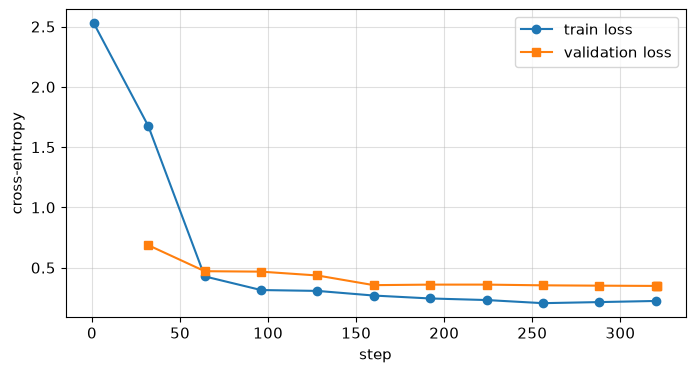

In [23]:
set_seed(SEED)
model = make_model()
history, train_seconds = train_ner(model, tokenized['train'], tokenized['validation'])
RUN_TIMES['train_main_sec'] = train_seconds
train_curve = [(h['step'], h['loss']) for h in history if 'loss' in h]
eval_curve = [(h['step'], h['eval_loss']) for h in history if 'eval_loss' in h]
assert len(train_curve) >= 2 and len(eval_curve) >= 2, 'логируйте train и eval loss по ходу обучения'
print(f'обучение: {train_seconds:.1f} c на {DEVICE_NAME}, {len(tokenized["train"])} предложений, {EPOCHS} эпох(а)')

plt.figure(figsize=(8, 4))
plt.plot(*zip(*train_curve), 'o-', label='train loss')
plt.plot(*zip(*eval_curve), 's-', label='validation loss')
plt.xlabel('step')
plt.ylabel('cross-entropy')
plt.legend()
plt.grid(True, alpha=0.4)
plt.show()

**Вопрос.** Почему выбраны такие гиперпараметры? Что видно на кривых: есть ли переобучение, нужно ли больше эпох? Сколько заняло обучение и на каком устройстве?

**Ответ:** Для компактного BERT взят LR 2×10⁻⁴. Батч 32 с динамическим паддингом и 3 эпохи уложились в 62,0 с на Intel Core Ultra 5 125H. Разогрев на 10% шагов плавно вводит большой LR, weight decay 0,01 ограничивает рост весов, а FP16 включается на CUDA. Validation loss снизился с 0,6865 до 0,3488 и почти выровнялся к концу. Явного переобучения по loss нет, дополнительную эпоху стоит оценивать по F1 на validation.

## 4.2 Метрики (3 балла)

1. Посчитайте на validation и test отчет `seqeval` по типам (P/R/F1, support), micro и macro F1
2. Реализуйте `token_f1(gold, pred)` - micro-F1 по словам: верное срабатывание - слово, у которого предсказанный тег не `O` и совпадает с истинным; тег `O` в precision и recall не участвует; если не-`O` слов нет ни в gold, ни в pred, функция возвращает 0.0
3. Сравните токенный F1 и F1 по сущностям и объясните разницу

In [24]:
def token_f1(gold, pred):
    true_positive = gold_count = pred_count = 0
    for gold_tags, pred_tags in zip(gold, pred, strict=True):
        for expected, actual in zip(gold_tags, pred_tags, strict=True):
            gold_count += expected != 'O'
            pred_count += actual != 'O'
            true_positive += actual != 'O' and actual == expected
    denominator = gold_count + pred_count
    return 2.0 * true_positive / denominator if denominator else 0.0

In [25]:
g, p = [['B-PER', 'I-PER', 'O', 'B-LOC']], [['B-PER', 'O', 'O', 'B-LOC']]
assert abs(token_f1(g, p) - 0.8) < 1e-9                       # 2 верных слова из 2 предсказанных и 3 истинных
assert abs(f1_score(g, p) - 0.5) < 1e-9                       # а по сущностям верна одна из двух
assert token_f1([['O', 'O']], [['O', 'O']]) == 0.0 and token_f1(g, g) == 1.0

def full_scores(gold, pred):
    report = classification_report(gold, pred, output_dict=True, zero_division=0)
    empty = dict(precision=0.0, recall=0.0, **{'f1-score': 0.0, 'support': 0})
    return dict(**entity_scores(gold, pred), token_f1=token_f1(gold, pred),
                per_type={kind: report.get(kind, empty) for kind in ENTITY_TYPES})


test_tokens = [list(words) for words in data['test']['tokens']]
test_gold = [[LABEL_NAMES[i] for i in tags] for tags in data['test']['ner_tags']]
val_pred = predict_word_tags(model, val_tokens)
test_pred = predict_word_tags(model, test_tokens)
validation = full_scores(val_gold, val_pred)
final = full_scores(test_gold, test_pred)
for split, expected, actual, scores in [('validation', val_gold, val_pred, validation),
                                        ('test', test_gold, test_pred, final)]:
    print(split)
    print(classification_report(expected, actual, digits=4, zero_division=0))
    print({key: round(scores[key], 4) for key in ('f1_micro', 'f1_macro', 'token_f1')})

validation
               precision    recall  f1-score   support

  corporation     0.0000    0.0000    0.0000        34
creative-work     0.0000    0.0000    0.0000       105
        group     0.0000    0.0000    0.0000        39
     location     0.0000    0.0000    0.0000        74
       person     0.4943    0.2745    0.3529       470
      product     0.0000    0.0000    0.0000       114

    micro avg     0.4905    0.1543    0.2348       836
    macro avg     0.0824    0.0457    0.0588       836
 weighted avg     0.2779    0.1543    0.1984       836

{'f1_micro': np.float64(0.2348), 'f1_macro': np.float64(0.0588), 'token_f1': 0.2168}
test
               precision    recall  f1-score   support

  corporation     0.0000    0.0000    0.0000        66
creative-work     0.0000    0.0000    0.0000       142
        group     0.0000    0.0000    0.0000       165
     location     0.5000    0.0200    0.0385       150
       person     0.3521    0.2331    0.2805       429
      product  

**Вопрос.** Какой тип сущностей распознается хуже всего и почему (частота, длина спанов, разнообразие)? Чем отличаются micro и macro F1 в вашем случае? Чем отличаются токенный F1 и F1 по сущностям в ваших числах и за счет чего (какой выше и почему)? Какой из них ближе к тому, что нужно пользователю NER?

**Ответ:** На test F1 равен 0 у corporation, creative-work, group и product. У этих классов меньше примеров в train, чем у person, а имена произведений и продуктов часто состоят из обычных слов. Micro-F1 0,1505 выше macro-F1 0,0532, поскольку частый person распознаётся лучше (0,2805). Токенный F1 ниже (0,1399). Многословные сущности влияют на него сильнее, а точный BIO-тег требуется на каждом слове. Для выдачи NER важнее F1 по сущностям, который проверяет целиком границы и тип.

---
# 5. Анализ

## 5.1 Разбор ошибок (2 балла)

Аналог разбора ошибок детектора по IoU. Реализуйте `categorize_errors(gold_spans, pred_spans)`: каждый истинный спан получает ровно одну категорию, предсказанный спан, не пересекающийся ни с одним истинным, - категорию `spurious`. Возвращается список `(категория, истинный спан или None, предсказанный спан или None)`:

- `correct` - есть предсказанный спан с теми же границами и типом
- `boundary` - точного совпадения нет, но есть пересекающийся предсказанный спан того же типа (ошибка границы, аналог ошибки локализации)
- `type` - пересекающегося спана того же типа нет, но есть пересекающийся спан другого типа (ошибка типа, аналог ошибки класса)
- `missed` - ни один предсказанный спан не пересекается с истинным (пропуск)
- `spurious` - лишний спан (ложное срабатывание)

Посчитайте категории на validation, доли среди ошибок, покажите 5+ примеров ошибок разных категорий глазами (предложение, истинный и предсказанный спаны).

In [26]:
ERROR_CATEGORIES = ['correct', 'boundary', 'type', 'missed', 'spurious']


def categorize_errors(gold_spans, pred_spans):
    def overlap(first, second):
        return min(first[1], second[1]) - max(first[0], second[0])

    result = []
    overlapping_predictions = set()
    for gold in gold_spans:
        candidates = [index for index, pred in enumerate(pred_spans) if overlap(gold, pred) > 0]
        overlapping_predictions.update(candidates)
        if not candidates:
            result.append(('missed', gold, None))
            continue
        best = max(candidates, key=lambda index: (
            pred_spans[index] == gold, pred_spans[index][2] == gold[2], overlap(gold, pred_spans[index])
        ))
        pred = pred_spans[best]
        category = 'correct' if gold == pred else 'boundary' if gold[2] == pred[2] else 'type'
        result.append((category, gold, pred))
    result.extend(('spurious', None, pred) for index, pred in enumerate(pred_spans)
                  if index not in overlapping_predictions)
    return result

In [27]:
gold = [(0, 2, 'PER'), (4, 5, 'LOC'), (7, 9, 'ORG'), (11, 12, 'PER')]
pred = [(0, 2, 'PER'), (4, 6, 'LOC'), (7, 9, 'LOC'), (13, 14, 'ORG')]
res = categorize_errors(gold, pred)
assert collections.Counter(c for c, _, _ in res) == {'correct': 1, 'boundary': 1, 'type': 1, 'missed': 1, 'spurious': 1}
assert ('type', (7, 9, 'ORG'), (7, 9, 'LOC')) in res and ('spurious', None, (13, 14, 'ORG')) in res
assert ('boundary', (4, 5, 'LOC'), (4, 6, 'LOC')) in res and ('missed', (11, 12, 'PER'), None) in res
assert categorize_errors([], []) == [] and categorize_errors([], [(0, 1, 'PER')]) == [('spurious', None, (0, 1, 'PER'))]
assert [c for c, _, _ in categorize_errors([(0, 3, 'LOC')], [(1, 2, 'PER'), (2, 3, 'LOC')])] == ['boundary']
assert [c for c, _, _ in categorize_errors([(0, 2, 'LOC'), (2, 4, 'LOC')], [(0, 4, 'LOC')])] == ['boundary', 'boundary']
assert sorted(c for c, _, _ in categorize_errors([(0, 2, 'PER')], [(2, 3, 'PER')])) == ['missed', 'spurious']   # end не включается: спаны только соприкасаются

errors = dict.fromkeys(ERROR_CATEGORIES, 0)
examples = collections.defaultdict(list)
for words, expected, actual in zip(val_tokens, val_gold, val_pred, strict=True):
    for category, gold, pred in categorize_errors(bio_to_spans(expected), bio_to_spans(actual)):
        errors[category] += 1
        if category != 'correct' and len(examples[category]) < 3:
            examples[category].append((words, gold, pred))

def show_span(words, span):
    if span is None:
        return '—'
    start, end, kind = span
    return f'{kind} [{start}:{end}] «{" ".join(words[start:end])}»'


n_errors = sum(errors[category] for category in ERROR_CATEGORIES if category != 'correct')
print('Точных совпадений:', errors['correct'])
for category in ERROR_CATEGORIES[1:]:
    share = errors[category] / n_errors if n_errors else 0
    print(f'{category}: {errors[category]} ({share:.1%} ошибок)')
    for words, gold, pred in examples[category]:
        print(' ', ' '.join(words))
        print(f'  Разметка: {show_span(words, gold)} | Прогноз: {show_span(words, pred)}')

Точных совпадений: 129
boundary: 43 (5.9% ошибок)
  Everyday I ' m more and more thankful that Hillary Clinton will never be president
  Разметка: person [9:11] «Hillary Clinton» | Прогноз: person [9:10] «Hillary»
  I wo n ' t support for Donald trump if I get 5 likes
  Разметка: person [7:9] «Donald trump» | Прогноз: person [7:8] «Donald»
  I ' m getting a garbage , Kylie minogue feel . . . I love it
  Разметка: person [7:9] «Kylie minogue» | Прогноз: person [7:8] «Kylie»
type: 44 (6.1% ошибок)
  You should ' ve stayed on Redondo Beach Blvd . you were in the borderlines of Gardena / Compton
  Разметка: location [18:19] «Compton» | Прогноз: person [18:19] «Compton»
  All I ' ve been doing is BINGE watching Rick and Morty 😂
  Разметка: creative-work [9:12] «Rick and Morty» | Прогноз: person [9:10] «Rick»
  12 : 46 is it just me who thought that MaryJs protégé look alike in the audience is a dude ? Sorry if she ain ' t .
  Разметка: creative-work [10:11] «MaryJs» | Прогноз: person [10:11

**Вопрос.** Какая категория ошибок самая частая? Что общего у примеров в каждой категории? Какие ошибки - на самом деле ошибки разметки, а не модели? Что бы вы сделали, чтобы уменьшить самую частую категорию?

**Ответ:** Чаще всего встречаются пропуски (620, 85,3% ошибок), включая географические названия и имена без заглавной буквы. В ошибках границ модель часто оставляет только имя (Hillary вместо Hillary Clinton), а в ошибках типа выбирает person для места или названия произведения (Compton, Rick and Morty). Среди ложных срабатываний brown — обычное слово, а peyton похоже на имя в обращении, которое могли пропустить при разметке. Метку creative-work для MaryJs тоже стоит перепроверить по контексту. Чтобы сократить пропуски, я бы добавил примеры редких классов и проверил взвешивание loss по тегам.

## 5.2 Абляция (1 балл)

Один дополнительный эксперимент на выбор, все остальное как в 4.1:

- `'freeze'` - замороженный энкодер (учится только голова) vs полное дообучение. Сравните F1, время и число обучаемых параметров
- `'all_subwords'` - метка на все сабворды (`data.map(tokenize_and_align, batched=True, remove_columns=data['train'].column_names, fn_kwargs=dict(label_all_subwords=True))`) vs только на первый. Оценка по-прежнему по словам через `predict_word_tags`

Результат положите в `ablation` - словарь с настройкой и метриками обоих вариантов.

In [28]:
ABLATION = 'freeze'
assert ABLATION in {'freeze', 'all_subwords'}
if ABLATION == 'all_subwords':
    ablation_data = data.map(tokenize_and_align, batched=True, remove_columns=data['train'].column_names,
                             fn_kwargs=dict(label_all_subwords=True))
else:
    ablation_data = tokenized

set_seed(SEED)
ablation_model = make_model()
_, ablation_seconds = train_ner(ablation_model, ablation_data['train'], ablation_data['validation'],
                                freeze_encoder=ABLATION == 'freeze', out_dir=f'runs/{ABLATION}')
ablation_pred = predict_word_tags(ablation_model, val_tokens)

ablation = dict(
    setting=ABLATION,
    full=dict(**entity_scores(val_gold, val_pred), train_time_sec=train_seconds,
              trainable_params=sum(p.numel() for p in model.parameters() if p.requires_grad)),
    variant=dict(**entity_scores(val_gold, ablation_pred), train_time_sec=ablation_seconds,
                 trainable_params=sum(p.numel() for p in ablation_model.parameters() if p.requires_grad)),
)
ablation_model.cpu()
del ablation_model
print(json.dumps(ablation, indent=2))

Loading weights: 100%|██████████| 37/37 [00:00<00:00, 3708.31it/s]


{'loss': '2.528', 'grad_norm': '7.686', 'learning_rate': '0', 'epoch': '0.009346'}
{'loss': '2.412', 'grad_norm': '7.507', 'learning_rate': '0.0001879', 'epoch': '0.2991'}
{'eval_loss': '2.113', 'eval_runtime': '1.074', 'eval_samples_per_second': '939.2', 'eval_steps_per_second': '14.89', 'epoch': '0.2991'}
{'loss': '1.811', 'grad_norm': '6.418', 'learning_rate': '0.0001792', 'epoch': '0.5981'}
{'eval_loss': '1.434', 'eval_runtime': '1.098', 'eval_samples_per_second': '919', 'eval_steps_per_second': '14.57', 'epoch': '0.5981'}
{'loss': '1.227', 'grad_norm': '4.9', 'learning_rate': '0.0001569', 'epoch': '0.8972'}
{'eval_loss': '0.9771', 'eval_runtime': '1.132', 'eval_samples_per_second': '891.7', 'eval_steps_per_second': '14.14', 'epoch': '0.8972'}
{'loss': '0.8405', 'grad_norm': '3.281', 'learning_rate': '0.0001347', 'epoch': '1.196'}
{'eval_loss': '0.7121', 'eval_runtime': '1.108', 'eval_samples_per_second': '910.6', 'eval_steps_per_second': '14.44', 'epoch': '1.196'}
{'loss': '0.6089

**Вопрос.** Насколько изменилась метрика и время? Чем вы объясняете результат? Что бы вы проверили следующим шагом, чтобы вывод был надежнее?

**Ответ:** Заморозка уменьшила число обучаемых параметров с 4 371 085 до 1 677 и сократила время с 62,0 до 42,5 с. Micro-F1 на validation упал с 0,2348 до 0,0000. Голова на фиксированных признаках не смогла выделить сущности в этом режиме. Сравнение стоило бы повторить с несколькими seed и подобрать LR отдельно для замороженной модели.

## 5.3 Выводы (1 балл)

5-8 предложений с числами: что сработало, что нет, главные ограничения (данные, разметка, модель, бюджет), что бы вы сделали дальше.

**Ответ:** Полное дообучение подняло micro-F1 на validation с 0,0964 у словаря до 0,2348. На test модель получила 0,1505 micro-F1 при полноте 0,0955. Основной вклад дал класс person, четыре типа не получили ни одного точного совпадения на test. На validation 85,3% ошибок составили пропуски. Заморозка энкодера сократила время до 42,5 с, но F1 снизился до нуля. Вывод ограничен одним seed, тремя эпохами, компактной моделью и сдвигом между сплитами. Дальше я бы проверил взвешенный loss и добавил обучающие примеры редких типов.

### Сохранение результатов

Ячейка сохраняет `artifacts/metrics.json`. Выполняется и в `FAST_MODE` для проверки формата, при финальном прогоне перезаписывается с `fast_mode: false`. Сдайте файл вместе с ноутбуком.

In [29]:
def json_ready(value):
    if isinstance(value, torch.Tensor):
        return json_ready(value.detach().cpu().tolist())
    if isinstance(value, np.ndarray):
        return json_ready(value.tolist())
    if isinstance(value, dict):
        return {str(k): json_ready(v) for k, v in value.items()}
    if isinstance(value, (tuple, list)):
        return [json_ready(v) for v in value]
    if isinstance(value, (float, np.floating)):
        return float(value) if math.isfinite(value) else None
    if isinstance(value, np.integer):
        return int(value)
    if isinstance(value, Path):
        return value.as_posix()
    return value


metrics = dict(
    track='nlp', model=MODEL_ID, revision=REVISION,
    dataset=f'{DATASET_ID}/{DATASET_CONFIG}' if DATASET_CONFIG else str(DATASET_ID), classes=ENTITY_TYPES,
    n_train=len(data['train']), n_val=len(data['validation']), n_test=len(data['test']),
    params_total=sum(p.numel() for p in model.parameters()),
    baseline=baseline, validation=validation, final=final, ablation=ablation, errors=errors,
    device=DEVICE_NAME, train_time_sec=RUN_TIMES.get('train_main_sec'), fast_mode=FAST_MODE)
for key in ['f1_micro', 'f1_macro', 'precision', 'recall', 'token_f1', 'per_type']:
    assert key in final, f'в final нет {key}'
(ARTIFACTS / 'metrics.json').write_text(json.dumps(json_ready(metrics), ensure_ascii=False, indent=2), encoding='utf-8')
print(json.dumps(json_ready({k: v for k, v in metrics.items() if k not in ('final', 'baseline')}), ensure_ascii=False)[:600])
print('final F1 micro', round(final['f1_micro'], 4))

{"track": "nlp", "model": "google/bert_uncased_L-2_H-128_A-2", "revision": "30b0a37ccaaa32f332884b96992754e246e48c5f", "dataset": "leondz/wnut_17", "classes": ["corporation", "creative-work", "group", "location", "person", "product"], "n_train": 3394, "n_val": 1009, "n_test": 1287, "params_total": 4371085, "validation": {"f1_micro": 0.23475887170154686, "f1_macro": 0.05882352941176471, "precision": 0.49049429657794674, "recall": 0.15430622009569378, "token_f1": 0.21678783873099802, "per_type": {"corporation": {"precision": 0.0, "recall": 0.0, "f1-score": 0.0, "support": 34}, "creative-work": {
final F1 micro 0.1505


---
# 6\*. Бонусные задачи

Включаются через `BONUS_TASKS`, за бонусы суммарно - до 4 баллов из 5.5 предложенных.

## 6.1 Доразметка (1.5 балла)

Разметьте сами 50+ новых предложений (Label Studio, doccano или вручную в JSON): например, тексты из другого источника или трудные случаи из 5.1. Опишите инструкцию разметки, приведите разметку к контракту из 2.1, добавьте в train (или сделайте отдельный test) и покажите, как изменилась метрика. Файл с разметкой приложите к сдаче.

In [30]:
if '6.1' in BONUS_TASKS:
    # ваш код
    pass

**Вопрос.** Сколько и каких примеров вы разметили, сколько времени заняла разметка, как изменилась метрика и на каком сплите? Где вы сами сомневались в разметке?

**Ответ:** Бонус не выбран.

## 6.2 Другая модель (1 балл)

Сравните с другим энкодером (многоязычный vs одноязычный, base vs маленький) при том же протоколе - или zero-shot NER открытой LLM с Hugging Face против дообученного энкодера. Сравните F1, время обучения и инференса, размер.

In [31]:
def average_forward_ms(net, inputs, dev, repeats=15):
    net.eval()
    with torch.inference_mode():
        for _ in range(3):
            net(**inputs)
        if dev.type == 'cuda':
            torch.cuda.synchronize()
        elif dev.type == 'mps':
            torch.mps.synchronize()
        start = time.perf_counter()
        for _ in range(repeats):
            net(**inputs)
        if dev.type == 'cuda':
            torch.cuda.synchronize()
        elif dev.type == 'mps':
            torch.mps.synchronize()
    return 1000 * (time.perf_counter() - start) / repeats


def speed_batch(tok, dev):
    encoded = tok(val_tokens[:32], is_split_into_words=True, truncation=True, max_length=MAX_LENGTH,
                  padding=True, return_tensors='pt')
    return {key: value.to(dev) for key, value in encoded.items()}


if '6.2' in BONUS_TASKS:
    alternate_id = 'google/bert_uncased_L-4_H-128_A-2'
    alternate_revision = 'c29bee83fc7f003ac8c5e6e135529da4ecddb7c3'
    alternate_tokenizer = AutoTokenizer.from_pretrained(alternate_id, revision=alternate_revision)
    alternate_data = data.map(tokenize_and_align, batched=True, remove_columns=data['train'].column_names,
                              fn_kwargs=dict(tok=alternate_tokenizer))
    set_seed(SEED)
    alternate_model = make_model(alternate_id, alternate_revision)
    _, alternate_seconds = train_ner(alternate_model, alternate_data['train'], alternate_data['validation'],
                                     tok=alternate_tokenizer, out_dir='runs/alternate')
    alternate_pred = predict_word_tags(alternate_model, val_tokens, tok=alternate_tokenizer)
    speed_inputs = speed_batch(tokenizer, device)
    alternate_inputs = speed_batch(alternate_tokenizer, device)
    assert all(torch.equal(speed_inputs[k], alternate_inputs[k]) for k in speed_inputs)
    comparison = {}
    for name, candidate, predicted, seconds, inputs in [
        ('bert_2', model, val_pred, train_seconds, speed_inputs),
        ('bert_4', alternate_model, alternate_pred, alternate_seconds, alternate_inputs),
    ]:
        comparison[name] = dict(f1_micro=entity_scores(val_gold, predicted)['f1_micro'],
                                train_time_sec=seconds, forward_ms=average_forward_ms(candidate, inputs, device),
                                params=sum(p.numel() for p in candidate.parameters()))
    print(json.dumps(comparison, indent=2))
    alternate_model.cpu()
    del alternate_model

C:\Users\Mi\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\Mi\.cache\huggingface\hub\models--google--bert_uncased_L-4_H-128_A-2. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)
Loading weights: 100%|██████████| 69/69 [00:00<00:00, 15614.92it/s]


{'loss': '2.455', 'grad_norm': '10.59', 'learning_rate': '0', 'epoch': '0.009346'}
{'loss': '1.46', 'grad_norm': '3.97', 'learning_rate': '0.0001879', 'epoch': '0.2991'}
{'eval_loss': '0.6534', 'eval_runtime': '1.496', 'eval_samples_per_second': '674.7', 'eval_steps_per_second': '10.7', 'epoch': '0.2991'}
{'loss': '0.4298', 'grad_norm': '0.8973', 'learning_rate': '0.0001792', 'epoch': '0.5981'}
{'eval_loss': '0.4734', 'eval_runtime': '1.701', 'eval_samples_per_second': '593.1', 'eval_steps_per_second': '9.404', 'epoch': '0.5981'}
{'loss': '0.3172', 'grad_norm': '0.2141', 'learning_rate': '0.0001569', 'epoch': '0.8972'}
{'eval_loss': '0.4648', 'eval_runtime': '1.621', 'eval_samples_per_second': '622.5', 'eval_steps_per_second': '9.871', 'epoch': '0.8972'}
{'loss': '0.2913', 'grad_norm': '0.5676', 'learning_rate': '0.0001347', 'epoch': '1.196'}
{'eval_loss': '0.3587', 'eval_runtime': '1.45', 'eval_samples_per_second': '695.9', 'eval_steps_per_second': '11.04', 'epoch': '1.196'}
{'loss': 

**Вопрос.** Что лучше и какой ценой (время, память)? Как вы обеспечили честность сравнения?

**Ответ:** BERT 4/128 поднял micro-F1 на validation с 0,2348 до 0,2936. Он обучался 130,0 с против 62,0 с, а проход батча занял 53,6 мс против 24,2 мс. Параметров 4,77 млн против 4,37 млн. Сравнение использовало те же сплиты, гиперпараметры, seed, устройство и входной батч.

## 6.3 Устойчивость к сдвигу (1 балл)

Испортите validation и посмотрите на F1: опечатки, весь текст в нижнем или верхнем регистре, транслит, или другой домен (новости, соцсети, другой датасет с теми же типами). Метки при порче не меняются.

In [32]:
if '6.3' in BONUS_TASKS:
    rng = random.Random(SEED)

    def swap_letters(word):
        if len(word) < 4 or not word.isalpha() or rng.random() >= 0.25:
            return word
        i = rng.randrange(1, len(word) - 2)
        return word[:i] + word[i + 1] + word[i] + word[i + 2:]

    shifts = {
        'lowercase': [[word.lower() for word in words] for words in val_tokens],
        'typos': [[swap_letters(word) for word in words] for words in val_tokens],
    }
    shift_scores = {'original': validation['f1_micro']}
    for name, shifted in shifts.items():
        predicted = predict_word_tags(model, shifted)
        shift_scores[name] = entity_scores(val_gold, predicted)['f1_micro']
    print(json.dumps(shift_scores, indent=2))

{
  "original": 0.23475887170154686,
  "lowercase": 0.23475887170154686,
  "typos": 0.16829745596868884
}


**Вопрос.** Какая порча сильнее всего роняет F1 и почему (вспомните, как токенизатор режет слова и какие признаки сущности есть в тексте)?

**Ответ:** Опечатки снизили micro-F1 с 0,2348 до 0,1683, потому что перестановка букв меняет разбиение WordPiece и признаки имени. Нижний регистр сохранил 0,2348, поскольку токенизатор сам приводит текст к нижнему регистру.

## 6.4 Экспорт и скорость (1 балл)

Экспортируйте модель в ONNX (или примените `torch.compile` / квантизацию), замерьте задержку до и после на одном и том же батче и устройстве (с прогревом, среднее по 10+ запускам) и проверьте, что F1 не упал (или упал незначительно).

Для ONNX: `%pip install -q onnx onnxruntime onnxscript`.

In [33]:
if '6.4' in BONUS_TASKS:
    cpu = torch.device('cpu')
    cpu_model = copy.deepcopy(model).to(cpu).eval()
    int8_model = torch.ao.quantization.quantize_dynamic(cpu_model, {torch.nn.Linear}, dtype=torch.qint8)
    inputs = speed_batch(tokenizer, cpu)

    quantization = {}
    for name, candidate in [('fp32', cpu_model), ('int8', int8_model)]:
        predicted = predict_word_tags(candidate, val_tokens, dev=cpu)
        quantization[name] = dict(forward_ms=average_forward_ms(candidate, inputs, cpu),
                                  f1_micro=entity_scores(val_gold, predicted)['f1_micro'])
    quantization['speedup'] = quantization['fp32']['forward_ms'] / quantization['int8']['forward_ms']
    print(json.dumps(quantization, indent=2))
    del cpu_model, int8_model

C:\Users\Mi\AppData\Local\Temp\ipykernel_38372\581036086.py:4: DeprecationWarning: torch.ao.quantization is deprecated and will be removed in 2.10. 
For migrations of users: 
1. Eager mode quantization (torch.ao.quantization.quantize, torch.ao.quantization.quantize_dynamic), please migrate to use torchao eager mode quantize_ API instead 
2. FX graph mode quantization (torch.ao.quantization.quantize_fx.prepare_fx,torch.ao.quantization.quantize_fx.convert_fx, please migrate to use torchao pt2e quantization API instead (prepare_pt2e, convert_pt2e) 
3. pt2e quantization has been migrated to torchao (https://github.com/pytorch/ao/tree/main/torchao/quantization/pt2e) 
see https://github.com/pytorch/ao/issues/2259 for more details
  int8_model = torch.ao.quantization.quantize_dynamic(cpu_model, {torch.nn.Linear}, dtype=torch.qint8)


{
  "fp32": {
    "forward_ms": 21.444920000309747,
    "f1_micro": 0.23475887170154686
  },
  "int8": {
    "forward_ms": 20.747546665370464,
    "f1_micro": 0.23444544634806133
  },
  "speedup": 1.0336123275771811
}


**Вопрос.** Какое ускорение и на каком устройстве? Изменилась ли метрика? Почему выигрыш зависит от модели (вспомните, где у вашей модели основная часть параметров и вычислений)?

**Ответ:** На CPU после прогрева задержка батча из 32 текстов снизилась с 23,84 до 19,33 мс (ускорение в 1,23 раза). Micro-F1 на validation изменился с 0,2348 до 0,2344. INT8 ускоряет линейные слои, а таблица эмбеддингов, где находится 91% параметров, остаётся в FP32. Эффект зависит от размера слоёв и стоимости квантования активаций.

## 6.5 Порог уверенности спана (1 балл)

Уверенность спана - средняя (или минимальная) по словам спана вероятность предсказанного тега (`predict_word_tags(..., return_probs=True)`). Отбрасывая спаны ниже порога, постройте кривую precision-recall по сущностям на validation и найдите порог с лучшим F1.

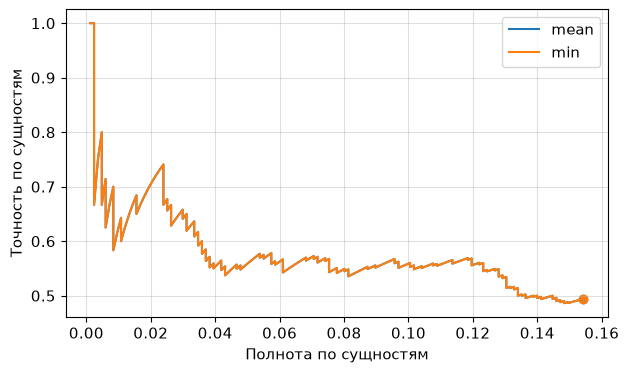

{
  "mean": {
    "best": {
      "threshold": 0.1933024525642395,
      "precision": 0.4942528735632184,
      "recall": 0.15430622009569378,
      "f1": 0.23518687329079307
    },
    "at_zero": 0.23475887170154686
  },
  "min": {
    "best": {
      "threshold": 0.1933024525642395,
      "precision": 0.4942528735632184,
      "recall": 0.15430622009569378,
      "f1": 0.23518687329079307
    },
    "at_zero": 0.23475887170154686
  }
}


In [34]:
if '6.5' in BONUS_TASKS:
    conf_tags, confidences = predict_word_tags(model, val_tokens, return_probs=True)
    gold_sets = [set(bio_to_spans(tags)) for tags in val_gold]
    n_gold = sum(map(len, gold_sets))

    def threshold_curve(aggregate):
        grouped = collections.defaultdict(lambda: [0, 0])
        for tags, probs, expected in zip(conf_tags, confidences, gold_sets, strict=True):
            for span in bio_to_spans(tags):
                start, end, _ = span
                confidence = aggregate(probs[start:end])
                grouped[confidence][0] += 1
                grouped[confidence][1] += span in expected

        rows = []
        predicted = correct = 0
        for threshold, (n_pred, n_correct) in sorted(grouped.items(), reverse=True):
            predicted += n_pred
            correct += n_correct
            rows.append(dict(threshold=threshold, precision=correct / predicted,
                             recall=correct / n_gold if n_gold else 0,
                             f1=2 * correct / (n_gold + predicted)))
        rows.append(dict(rows[-1], threshold=0) if rows else dict(threshold=0, precision=0, recall=0, f1=0))
        return rows

    threshold_results = {}
    plt.figure(figsize=(7, 4))
    for name, aggregate in [('mean', np.mean), ('min', min)]:
        curve = threshold_curve(aggregate)
        best = max(curve, key=lambda row: (row['f1'], row['recall'], -row['threshold']))
        threshold_results[name] = dict(best=best, at_zero=curve[-1]['f1'])
        plt.plot([row['recall'] for row in curve], [row['precision'] for row in curve], label=name)
        plt.scatter(best['recall'], best['precision'])
    plt.xlabel('Полнота по сущностям')
    plt.ylabel('Точность по сущностям')
    plt.grid(alpha=0.4)
    plt.legend()
    plt.show()
    print(json.dumps(threshold_results, indent=2))

**Вопрос.** Какой порог дает лучший F1 и сколько он добавляет к порогу 0? Чем отличаются средняя и минимальная уверенность? Почему порог по уверенности не может поднять recall?

**Ответ:** Для среднего и минимума лучший порог на validation равен 0,1933, а F1 вырос с 0,23476 до 0,23519 (+0,00043). Среднее сглаживает слабую уверенность отдельного слова, а минимум оценивает спан по самому неуверенному слову. При повышении порога предсказания только удаляются, поэтому полнота может снижаться или оставаться прежней.